# SDXL Inpainting

This notebook evaluates Stable Diffusion XL for replacing product backgrounds.
The ten input images must be in "products_images" folder.
Run the code cells in order using a GPU runtime.

In [ ]:
%pip install -q diffusers transformers accelerate safetensors sentencepiece matplotlib "pandas==2.2.3" "pillow>=11,<13" "protobuf>=5.29.1,<7"

In [ ]:
from pathlib import Path
from PIL import Image
import torch

# Checking GPU
assert torch.cuda.is_available(), "Enable the GPU first."
print("GPU:", torch.cuda.get_device_name(0))

# Reading folder
image_folder = Path("/content/products_images")
assert image_folder.exists(), "Image folder not found."

extensions = {".jpg", ".jpeg", ".png", ".webp", ".avif"}
image_paths = sorted(
    path for path in image_folder.iterdir()
    if path.is_file() and path.suffix.lower() in extensions
)

# Create result folders
project = Path("/content/image_comparison")

for name in ["inputs", "masks", "outputs", "results"]:
    (project / name).mkdir(parents=True, exist_ok=True)

# Check each image
for path in image_paths:
    with Image.open(path) as image:
        print(f"{path.name}: {image.size}")
        image.verify()

print(f"\nReady: {len(image_paths)} images")

GPU: Tesla T4
Coca_Cola.jpeg: (1200, 1200)
Coffee_cup.jpeg: (480, 480)
Doritos.webp: (1200, 1200)
KitKat.webp: (1200, 1200)
Mount_Franklin.jpeg: (1200, 1200)
Oreo.jpeg: (1200, 1200)
Pringles.jpg: (1200, 1200)
Red_Bull.jpg: (1200, 1200)
Red_Rock_Deli.jpeg: (1200, 1200)
Smiths_Orginal.jpg: (480, 480)

Ready: 10 images


## Prepare inputs

Images are adjusted in size while keeping their original shape and are positioned on a 768 × 768 canvas. White mask areas allow editing and black areas protect
the product. Enclosed mask holes are corrected before generation.

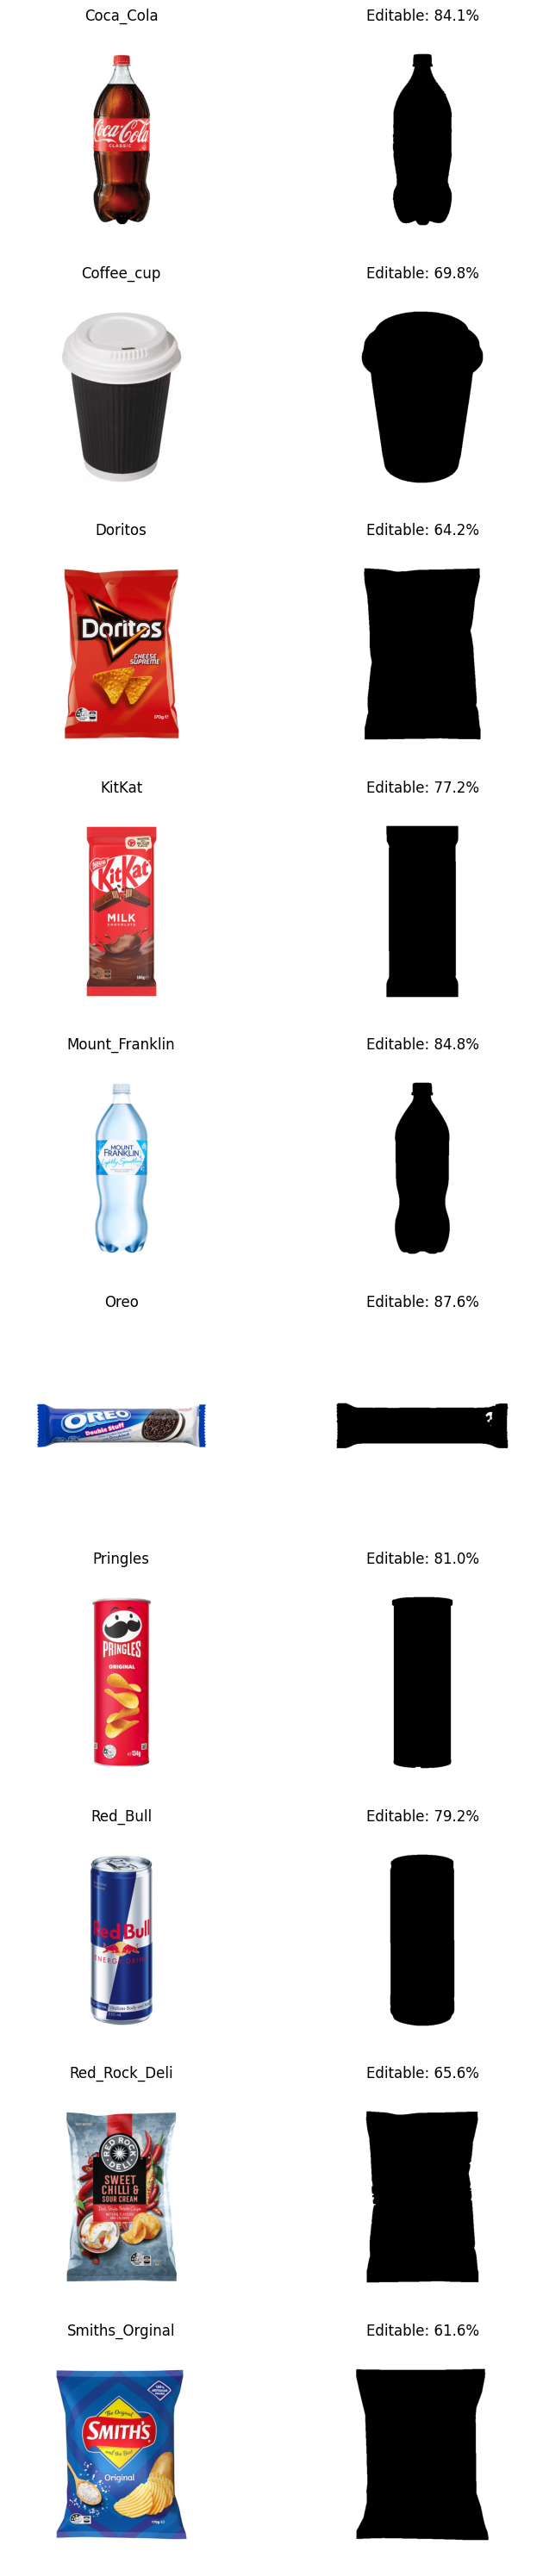

Prepared: 10 images


In [ ]:
from collections import deque
from PIL import ImageOps, ImageFilter
import numpy as np
import matplotlib.pyplot as plt

prepared_images = []

def make_mask(image):
    pixels = np.asarray(image)
    near_white = np.all(pixels >= 240, axis=2)
    height, width = near_white.shape

    # Find background from the outer corner
    background = np.zeros((height, width), dtype=bool)
    background[0, 0] = True
    queue = deque([(0, 0)])

    while queue:
        y, x = queue.popleft()

        for ny, nx in [(y-1, x), (y+1, x), (y, x-1), (y, x+1)]:
            if (
                0 <= ny < height
                and 0 <= nx < width
                and near_white[ny, nx]
                and not background[ny, nx]
            ):
                background[ny, nx] = True
                queue.append((ny, nx))

    # a small protective margin
    protected = Image.fromarray(
        (~background).astype(np.uint8) * 255
    ).filter(ImageFilter.MaxFilter(7))

    return ImageOps.invert(protected)


fig, axes = plt.subplots(10, 2, figsize=(8, 30))

for row, path in enumerate(image_paths):
    with Image.open(path) as source:
        source = ImageOps.exif_transpose(source).convert("RGBA")
        white = Image.new("RGBA", source.size, "white")
        source = Image.alpha_composite(white, source).convert("RGB")

    # Keep proportions and add space
    product = ImageOps.contain(
        source, (576, 576), Image.Resampling.LANCZOS
    )
    image = Image.new("RGB", (768, 768), "white")
    image.paste(
        product,
        ((768 - product.width) // 2, (768 - product.height) // 2)
    )

    mask = make_mask(image)
    editable = np.mean(np.asarray(mask) == 255)

    assert 0 < editable < 1, f"Invalid mask: {path.name}"

    image.save(project / "inputs" / f"{path.stem}.png")
    mask.save(project / "masks" / f"{path.stem}_mask.png")

    prepared_images.append({
        "name": path.stem,
        "image": image,
        "mask": mask,
    })

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(path.stem)
    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(f"Editable: {editable:.1%}")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(project / "results" / "mask_preview.png", dpi=120)
plt.show()

print("Prepared:", len(prepared_images), "images")

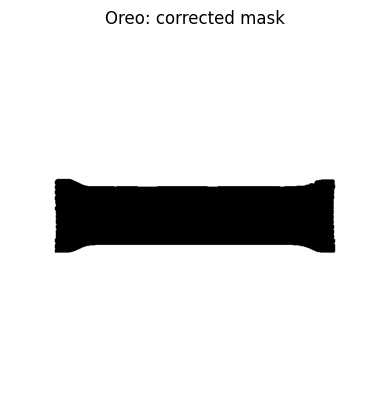

In [ ]:
from PIL import ImageDraw

for item in prepared_images:
    mask = item["mask"]

    # Mark the outer background
    connected = mask.copy()
    ImageDraw.floodfill(connected, (0, 0), value=128, thresh=0)

    # Protect enclosed white areas
    pixels = np.asarray(connected)
    fixed_mask = Image.fromarray(
        np.where(pixels == 128, 255, 0).astype(np.uint8)
    )

    item["mask"] = fixed_mask
    fixed_mask.save(
        project / "masks" / f"{item['name']}_mask.png"
    )

# Checking Oreo for better results
oreo = next(item for item in prepared_images if item["name"] == "Oreo")

plt.imshow(oreo["mask"], cmap="gray", vmin=0, vmax=255)
plt.title("Oreo: corrected mask")
plt.axis("off")
plt.show()

## Load the model

SDXL Inpainting is loaded in float16 with CPU offloading to reduce
GPU memory use.

In [ ]:
from diffusers import AutoPipelineForInpainting

model_a_id = "diffusers/stable-diffusion-xl-1.0-inpainting-0.1"

# Load model
pipe_a = AutoPipelineForInpainting.from_pretrained(
    model_a_id,
    dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
)

# Reduce GPU memory use
pipe_a.enable_model_cpu_offload()
pipe_a.vae.enable_slicing()
pipe_a.vae.enable_tiling()

print("SDXL loaded successfully.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SDXL loaded successfully.


## Pilot and diagnostic tests

One product is used to check the settings and mask behaviour.
These tests are excluded from the final comparison.

  0%|          | 0/24 [00:00<?, ?it/s]

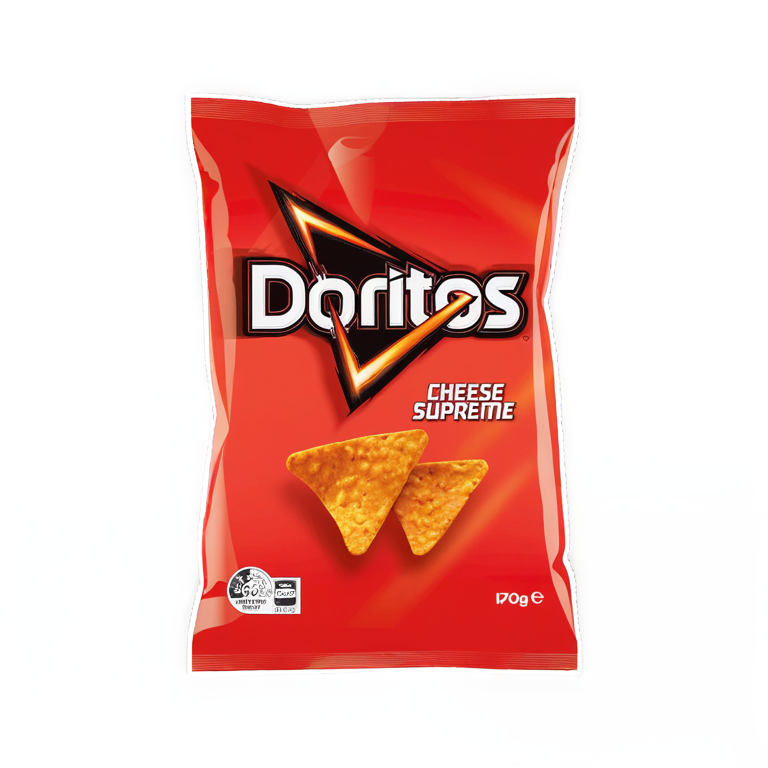

Runtime: 46.82 seconds
Peak GPU allocation: 5.23 GB
Protected-region MAE: 16.02


In [ ]:
import json
import time
from datetime import datetime, timezone
from IPython.display import display

item = next(x for x in prepared_images if x["name"] == "Doritos")

settings = {
    "prompt": (
        "A snack packet on a matte blue tabletop, "
        "solid dark blue background, blue studio backdrop, "
        "commercial product photography."
    ),
    "negative_prompt": (
        "extra products, people, hands, watermark, clutter, blurry"
    ),
    "num_inference_steps": 25,
    "guidance_scale": 7.5,
    "strength": 0.99,
    "width": 768,
    "height": 768,
}

seed = 42
run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
output_name = f"sdxl_Doritos_{run_id}.png"

# Measure inference
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()

with torch.inference_mode():
    result = pipe_a(
        image=item["image"],
        mask_image=item["mask"],
        generator=torch.Generator("cpu").manual_seed(seed),
        **settings,
    ).images[0]

torch.cuda.synchronize()
seconds = time.perf_counter() - start

# Save raw output
result.save(project / "outputs" / output_name)

original = np.asarray(item["image"], dtype=np.float32)
generated = np.asarray(result, dtype=np.float32)
protected = np.asarray(item["mask"]) == 0

mae = float(np.abs(generated - original)[protected].mean())

record = {
    "model": model_a_id,
    "product": item["name"],
    "seed": seed,
    "settings": settings,
    "scheduler": type(pipe_a.scheduler).__name__,
    "scheduler_config": dict(pipe_a.scheduler.config),
    "seconds": round(seconds, 2),
    "peak_allocated_gpu_gb": round(
        torch.cuda.max_memory_allocated() / 1024**3, 3
    ),
    "protected_region_mae": round(mae, 4),
    "output": output_name,
    "stage": "pilot",
}

(project / "results" / f"sdxl_{run_id}.json").write_text(
    json.dumps(record, indent=2, default=str)
)

display(result)
print("Runtime:", round(seconds, 2), "seconds")
print("Peak GPU allocation:", record["peak_allocated_gpu_gb"], "GB")
print("Protected-region MAE:", round(mae, 4))

  0%|          | 0/24 [00:00<?, ?it/s]

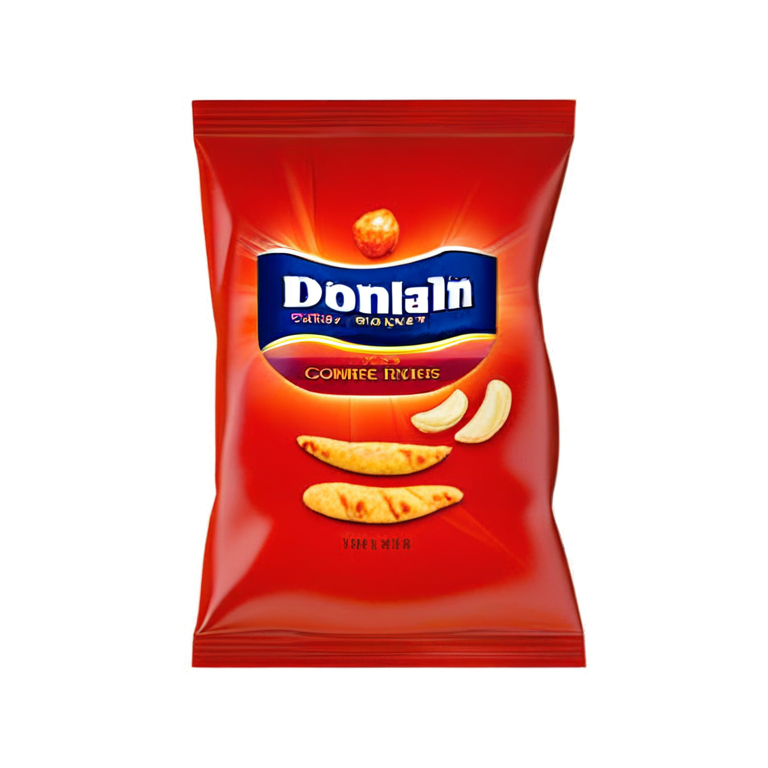

Diagnostic runtime: 18.15 seconds


In [ ]:
# Diagnostic only: allow editing everywhere
full_mask = Image.new("L", item["image"].size, 255)

torch.cuda.synchronize()
start = time.perf_counter()

with torch.inference_mode():
    diagnostic = pipe_a(
        image=item["image"],
        mask_image=full_mask,
        generator=torch.Generator("cpu").manual_seed(seed),
        **settings,
    ).images[0]

torch.cuda.synchronize()
seconds = time.perf_counter() - start

diagnostic_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")

diagnostic.save(
    project / "outputs" / f"full_mask_{diagnostic_id}.png"
)
full_mask.save(
    project / "masks" / f"full_mask_{diagnostic_id}.png"
)

diagnostic_record = {
    "purpose": "Check response when the whole image is editable",
    "model": model_a_id,
    "seed": seed,
    "settings": settings,
    "seconds": round(seconds, 2),
    "mask": "all white",
    "stage": "diagnostic, excluded from model comparison",
}

(project / "results" / f"full_mask_{diagnostic_id}.json").write_text(
    json.dumps(diagnostic_record, indent=2)
)

display(diagnostic)
print("Diagnostic runtime:", round(seconds, 2), "seconds")

  0%|          | 0/25 [00:00<?, ?it/s]

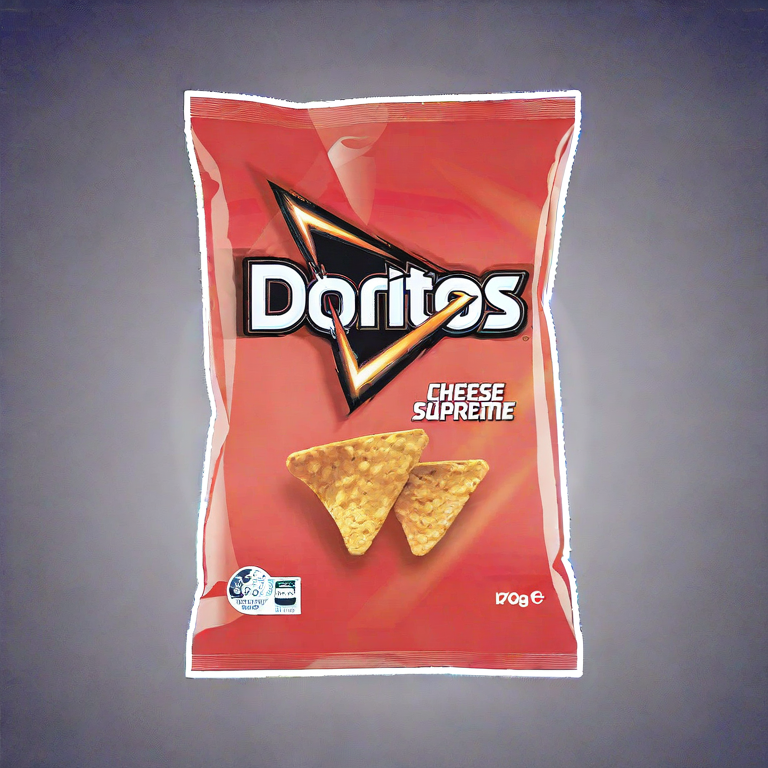

{
  "model": "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
  "product": "Doritos",
  "seed": 42,
  "settings": {
    "prompt": "A snack packet on a matte blue tabletop, solid dark blue background, blue studio backdrop, commercial product photography.",
    "negative_prompt": "extra products, people, hands, watermark, clutter, blurry",
    "num_inference_steps": 25,
    "guidance_scale": 7.5,
    "strength": 1.0,
    "width": 768,
    "height": 768
  },
  "scheduler": "EulerDiscreteScheduler",
  "seconds": 18.09,
  "peak_allocated_gpu_gb": 5.23,
  "protected_region_mae": 39.3822,
  "output": "sdxl_strength1_20261101_014747_185106.png",
  "stage": "strength diagnostic"
}


In [ ]:
# Change only strength
test_settings = settings.copy()
test_settings["strength"] = 1.0

test_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()

with torch.inference_mode():
    strength_test = pipe_a(
        image=item["image"],
        mask_image=item["mask"],
        generator=torch.Generator("cpu").manual_seed(seed),
        **test_settings,
    ).images[0]

torch.cuda.synchronize()
seconds = time.perf_counter() - start

output_name = f"sdxl_strength1_{test_id}.png"
strength_test.save(project / "outputs" / output_name)

original = np.asarray(item["image"], dtype=np.float32)
generated = np.asarray(strength_test, dtype=np.float32)
protected = np.asarray(item["mask"]) == 0

test_record = {
    "model": model_a_id,
    "product": item["name"],
    "seed": seed,
    "settings": test_settings,
    "scheduler": type(pipe_a.scheduler).__name__,
    "seconds": round(seconds, 2),
    "peak_allocated_gpu_gb": round(
        torch.cuda.max_memory_allocated() / 1024**3, 3
    ),
    "protected_region_mae": round(
        float(np.abs(generated - original)[protected].mean()), 4
    ),
    "output": output_name,
    "stage": "strength diagnostic",
}

(project / "results" / f"strength1_{test_id}.json").write_text(
    json.dumps(test_record, indent=2)
)

display(strength_test)
print(json.dumps(test_record, indent=2))

## Final experiment

Each of the ten products is tested with seeds 42 and 123, producing
20 outputs. The experiment uses 25 steps, guidance 7.5 and strength 1.0.
Runtime, peak GPU allocation and image-change metrics are saved.

In [ ]:
import pandas as pd

batch_settings = settings.copy()
batch_settings["strength"] = 1.0
seeds = [42, 123]

batch_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
batch_folder = project / "outputs" / f"sdxl_{batch_id}"
batch_folder.mkdir(parents=True, exist_ok=True)

rows = []

# Save settings before running
batch_config = {
    "model": model_a_id,
    "settings": batch_settings,
    "seeds": seeds,
    "products": [x["name"] for x in prepared_images],
    "scheduler": type(pipe_a.scheduler).__name__,
    "scheduler_config": dict(pipe_a.scheduler.config),
}

(project / "results" / f"sdxl_config_{batch_id}.json").write_text(
    json.dumps(batch_config, indent=2, default=str)
)

for product in prepared_images:
    for run_seed in seeds:
        print(f"Running {product['name']} | seed {run_seed}")

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()

        with torch.inference_mode():
            output = pipe_a(
                image=product["image"],
                mask_image=product["mask"],
                generator=torch.Generator("cpu").manual_seed(run_seed),
                **batch_settings,
            ).images[0]

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        filename = f"{product['name']}_seed{run_seed}.png"
        output.save(batch_folder / filename)

        before = np.asarray(product["image"], dtype=np.float32)
        after = np.asarray(output, dtype=np.float32)
        protected = np.asarray(product["mask"]) == 0
        editable = ~protected

        rows.append({
            "product": product["name"],
            "seed": run_seed,
            "seconds": round(elapsed, 2),
            "peak_allocated_gpu_gb": round(
                torch.cuda.max_memory_allocated() / 1024**3, 3
            ),
            "protected_mae": float(
                np.abs(after - before)[protected].mean()
            ),
            "background_mae": float(
                np.abs(after - before)[editable].mean()
            ),
            "output": str((batch_folder / filename).relative_to(project)),
        })

        # Save progress after every image
        pd.DataFrame(rows).to_csv(
            project / "results" / f"sdxl_metrics_{batch_id}.csv",
            index=False,
        )

print("Finished:", len(rows), "outputs")
display(pd.DataFrame(rows))

Running Coca_Cola | seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

Running Coca_Cola | seed 123


  0%|          | 0/25 [00:00<?, ?it/s]

Running Coffee_cup | seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

... (32 outputs left out)

Running Smiths_Orginal | seed 123


  0%|          | 0/25 [00:00<?, ?it/s]

Finished: 20 outputs


,product,seed,seconds,peak_allocated_gpu_gb,protected_mae,background_mae,output
0,Coca_Cola,42,20.98,5.23,31.844191,128.242157,outputs/sdxl_20261101_014905/Coca_Cola_seed42.png
1,Coca_Cola,123,19.75,5.23,35.535301,108.110100,outputs/sdxl_20261101_014905/Coca_Cola_seed123...
2,Coffee_cup,42,19.08,5.23,16.121086,134.127136,outputs/sdxl_20261101_014905/Coffee_cup_seed42...
3,Coffee_cup,123,18.04,5.23,29.074833,124.429146,outputs/sdxl_20261101_014905/Coffee_cup_seed12...
4,Doritos,42,18.51,5.23,39.382210,129.739227,outputs/sdxl_20261101_014905/Doritos_seed42.png
5,Doritos,123,19.33,5.23,56.637905,120.574585,outputs/sdxl_20261101_014905/Doritos_seed123.png
6,KitKat,42,18.82,5.23,19.313055,130.487289,outputs/sdxl_20261101_014905/KitKat_seed42.png
7,KitKat,123,18.22,5.23,34.805958,120.669380,outputs/sdxl_20261101_014905/KitKat_seed123.png
8,Mount_Franklin,42,18.48,5.23,22.290579,138.476669,outputs/sdxl_20261101_014905/Mount_Franklin_se...
9,Mount_Franklin,123,18.86,5.23,19.213430,126.943077,outputs/sdxl_20261101_014905/Mount_Franklin_se...


## Download results

The prepared inputs, masks, generated images, settings and measurements
are downloaded as "sdxl_batch_backup.zip". Download this notebook
separately to preserve the code and displayed results.

In [ ]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/sdxl_batch_backup",
    "zip",
    root_dir=str(project),
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>